In [36]:
import os
import re
import json
from dotenv import load_dotenv
import sys

In [37]:
project_root = "/home/mohammad/Documents/Codes/agentic_codes"
if project_root not in sys.path:
    sys.path.insert(0, project_root)

In [38]:
from utils import llm_helpers as utils

In [39]:
load_dotenv()

True

In [40]:
csv_path = os.path.join(project_root, "data", "coffee_sales.csv")
df = utils.load_and_prepare_data(csv_path)
utils.print_html(df.sample(n=5), title="Random Sample of Coffee Sales Data")

date,time,cash_type,card,price,coffee_name,quarter,month,year
2025-02-05,09:47,card,ANON-0000-0000-1171,2.106,Espresso,1,2,2025
2024-04-01,13:02,cash,NaN,4.000,Cappuccino,2,4,2024
2024-09-24,10:13,card,ANON-0000-0000-0583,3.282,Latte,3,9,2024
2025-01-05,06:51,card,ANON-0000-0000-1076,3.086,Americano with Milk,1,1,2025
2024-05-20,12:26,cash,NaN,2.900,Americano,2,5,2024


In [41]:
def generate_chart_code(instruction: str, model: str, out_path_v1: str) -> str:
    """Generate Python code to make a plot with matplotlib using tag-based wrapping."""

    prompt = f"""
    You are a data visualization expert.

    Return your answer *strictly* in this format:

    <execute_python>
    # valid python code here
    </execute_python>

    Do not add explanations, only the tags and the code.

    The code should create a visualization from a DataFrame 'df' with these columns:
    - date (M/D/YY)
    - time (HH:MM)
    - cash_type (card or cash)
    - card (string)
    - price (number)
    - coffee_name (string)
    - quarter (1-4)
    - month (1-12)
    - year (YYYY)

    User instruction: {instruction}

    Requirements for the code:
    1. Assume the DataFrame is already loaded as 'df'.
    2. Use matplotlib for plotting.
    3. Add clear title, axis labels, and legend if needed.
    4. Save the figure as '{out_path_v1}' with dpi=300.
    5. Do not call plt.show().
    6. Close all plots with plt.close().
    7. Add all necessary import python statements

    Return ONLY the code wrapped in <execute_python> tags.
    """
    
    response = utils.get_response(model, prompt)
    return response

In [42]:
def reflect_on_image_and_regenerate(
        chart_path: str,
        instruction: str,
        model_name: str,
        out_path_v2: str,
        code_v1: str,
    ) -> tuple[str, str]:
        
    media_type, b64 = utils.encode_image_b64(chart_path)


    prompt = f"""
        You are a data visualization expert.
        Your task: critique the attached chart and the original code against the given instruction,
        then return improved matplotlib code.

        Original code (for context):
        {code_v1}

        OUTPUT FORMAT (STRICT):
        1) First line: a valid JSON object with ONLY the "feedback" field.
        Example: {{"feedback": "The legend is unclear and the axis labels overlap."}}

        2) After a newline, output ONLY the refined Python code wrapped in:
        <execute_python>
        ...
        </execute_python>

        3) Import all necessary libraries in the code. Don't assume any imports from the original code.

        HARD CONSTRAINTS:
        - Do NOT include Markdown, backticks, or any extra prose outside the two parts above.
        - Use pandas/matplotlib only (no seaborn).
        - Assume df already exists; do not read from files.
        - Save to '{out_path_v2}' with dpi=300.
        - Always call plt.close() at the end (no plt.show()).
        - Include all necessary import statements.

        Schema (columns available in df):
        - date (M/D/YY)
        - time (HH:MM)
        - cash_type (card or cash)
        - card (string)
        - price (number)
        - coffee_name (string)
        - quarter (1-4)
        - month (1-12)
        - year (YYYY)

        Instruction:
        {instruction}
    """


    content = utils.image_groq_call(model_name, prompt, media_type, b64)

    lines = content.strip().splitlines()
    json_line = lines[0].strip() if lines else ""

    try:
        obj = json.loads(json_line)
    except Exception as e:
        # Fallback: try to capture the first {...} in all the content
        m_json = re.search(r"\{.*?\}", content, flags=re.DOTALL)
        if m_json:
            try:
                obj = json.loads(m_json.group(0))
            except Exception as e2:
                obj = {"feedback": f"Failed to parse JSON: {e2}", "refined_code": ""}
        else:
            obj = {"feedback": f"Failed to find JSON: {e}", "refined_code": ""}

    m_code = re.search(r"<execute_python>([\s\S]*?)</execute_python>", content)
    refined_code_body = m_code.group(1).strip() if m_code else ""
    refined_code = utils.ensure_execute_python_tags(refined_code_body)

    feedback = str(obj.get("feedback", "")).strip()
    return feedback, refined_code



In [46]:
def run_workflow(
        dataset_path: str,
        user_instructions: str,
        generation_model: str,
        reflection_model: str,
        image_basename: str = "chart",
    ):
    
    """
        End-to-end pipeline:
        1) load dataset
        2) generate V1 code
        3) execute V1 → produce chart_v1.png
        4) reflect on V1 (image + original code) → feedback + refined code
        5) execute V2 → produce chart_v2.png

        Returns a dict with all artifacts (codes, feedback, image paths).
    """

    df = utils.load_and_prepare_data(dataset_path)
    utils.print_html(df.sample(n=5), title="Random Sample of Dataset")

    # Paths to store charts
    out_v1 = f"{image_basename}_v1.png"
    out_v2 = f"{image_basename}_v2.png"

    # 1) Generate code (V1)
    utils.print_html("Step 1: Generating chart code (V1)… 📈")
    code_v1 = generate_chart_code(
        instruction=user_instructions,
        model=generation_model,
        out_path_v1=out_v1,
    )
    utils.print_html(code_v1, title="LLM output with first draft code (V1)")

    # 2) Execute V1 (hard-coded: extract <execute_python> block and run immediately)
    utils.print_html("Step 2: Executing chart code (V1)… 💻")
    match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v1)
    if match:
        initial_code = match.group(1).strip()
        exec_globals = {"df": df}
        exec(initial_code, exec_globals)
    utils.print_html(out_v1, is_image=True, title="Generated Chart (V1)")

    # 3) Reflect on V1 (image + original code) to get feedback and refined code (V2)
    utils.print_html("Step 3: Reflecting on V1 (image + code) and generating improvements… 🔁")
    feedback, code_v2 = reflect_on_image_and_regenerate(
        chart_path=out_v1,
        instruction=user_instructions,
        model_name=reflection_model,
        out_path_v2=out_v2,
        code_v1=code_v1,  # pass original code for context
    )
    utils.print_html(feedback, title="Reflection feedback on V1")
    utils.print_html(code_v2, title="LLM output with revised code (V2)")

    # 4) Execute V2 (hard-coded: extract <execute_python> block and run immediately)
    utils.print_html("Step 4: Executing refined chart code (V2)… 🖼️")
    match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v2)
    if match:
        reflected_code = match.group(1).strip()
        exec_globals = {"df": df}
        exec(reflected_code, exec_globals)
    utils.print_html(out_v2, is_image=True, title="Regenerated Chart (V2)")

    return {
        "code_v1": code_v1,
        "chart_v1": out_v1,
        "feedback": feedback,
        "code_v2": code_v2,
        "chart_v2": out_v2,
    }

In [47]:
user_instructions="Create a plot comparing Q1 coffee sales in 2024 and 2025 using the data in coffee_sales.csv." # write your instruction here
generation_model="openai/gpt-oss-120b"
reflection_model="qwen/qwen3.8-27b"
image_basename="drink_sales"

date,time,cash_type,card,price,coffee_name,quarter,month,year
2024-06-18,10:28,card,ANON-0000-0000-0310,2.792,Cortado,2,6,2024
2024-03-27,07:08,card,ANON-0000-0000-0003,3.380,Americano with Milk,1,3,2024
2024-09-29,07:51,card,ANON-0000-0000-0172,3.576,Cappuccino,3,9,2024
2024-05-15,15:27,cash,NaN,2.900,Americano,2,5,2024
2025-03-16,14:00,card,ANON-0000-0000-1294,3.576,Latte,1,3,2025



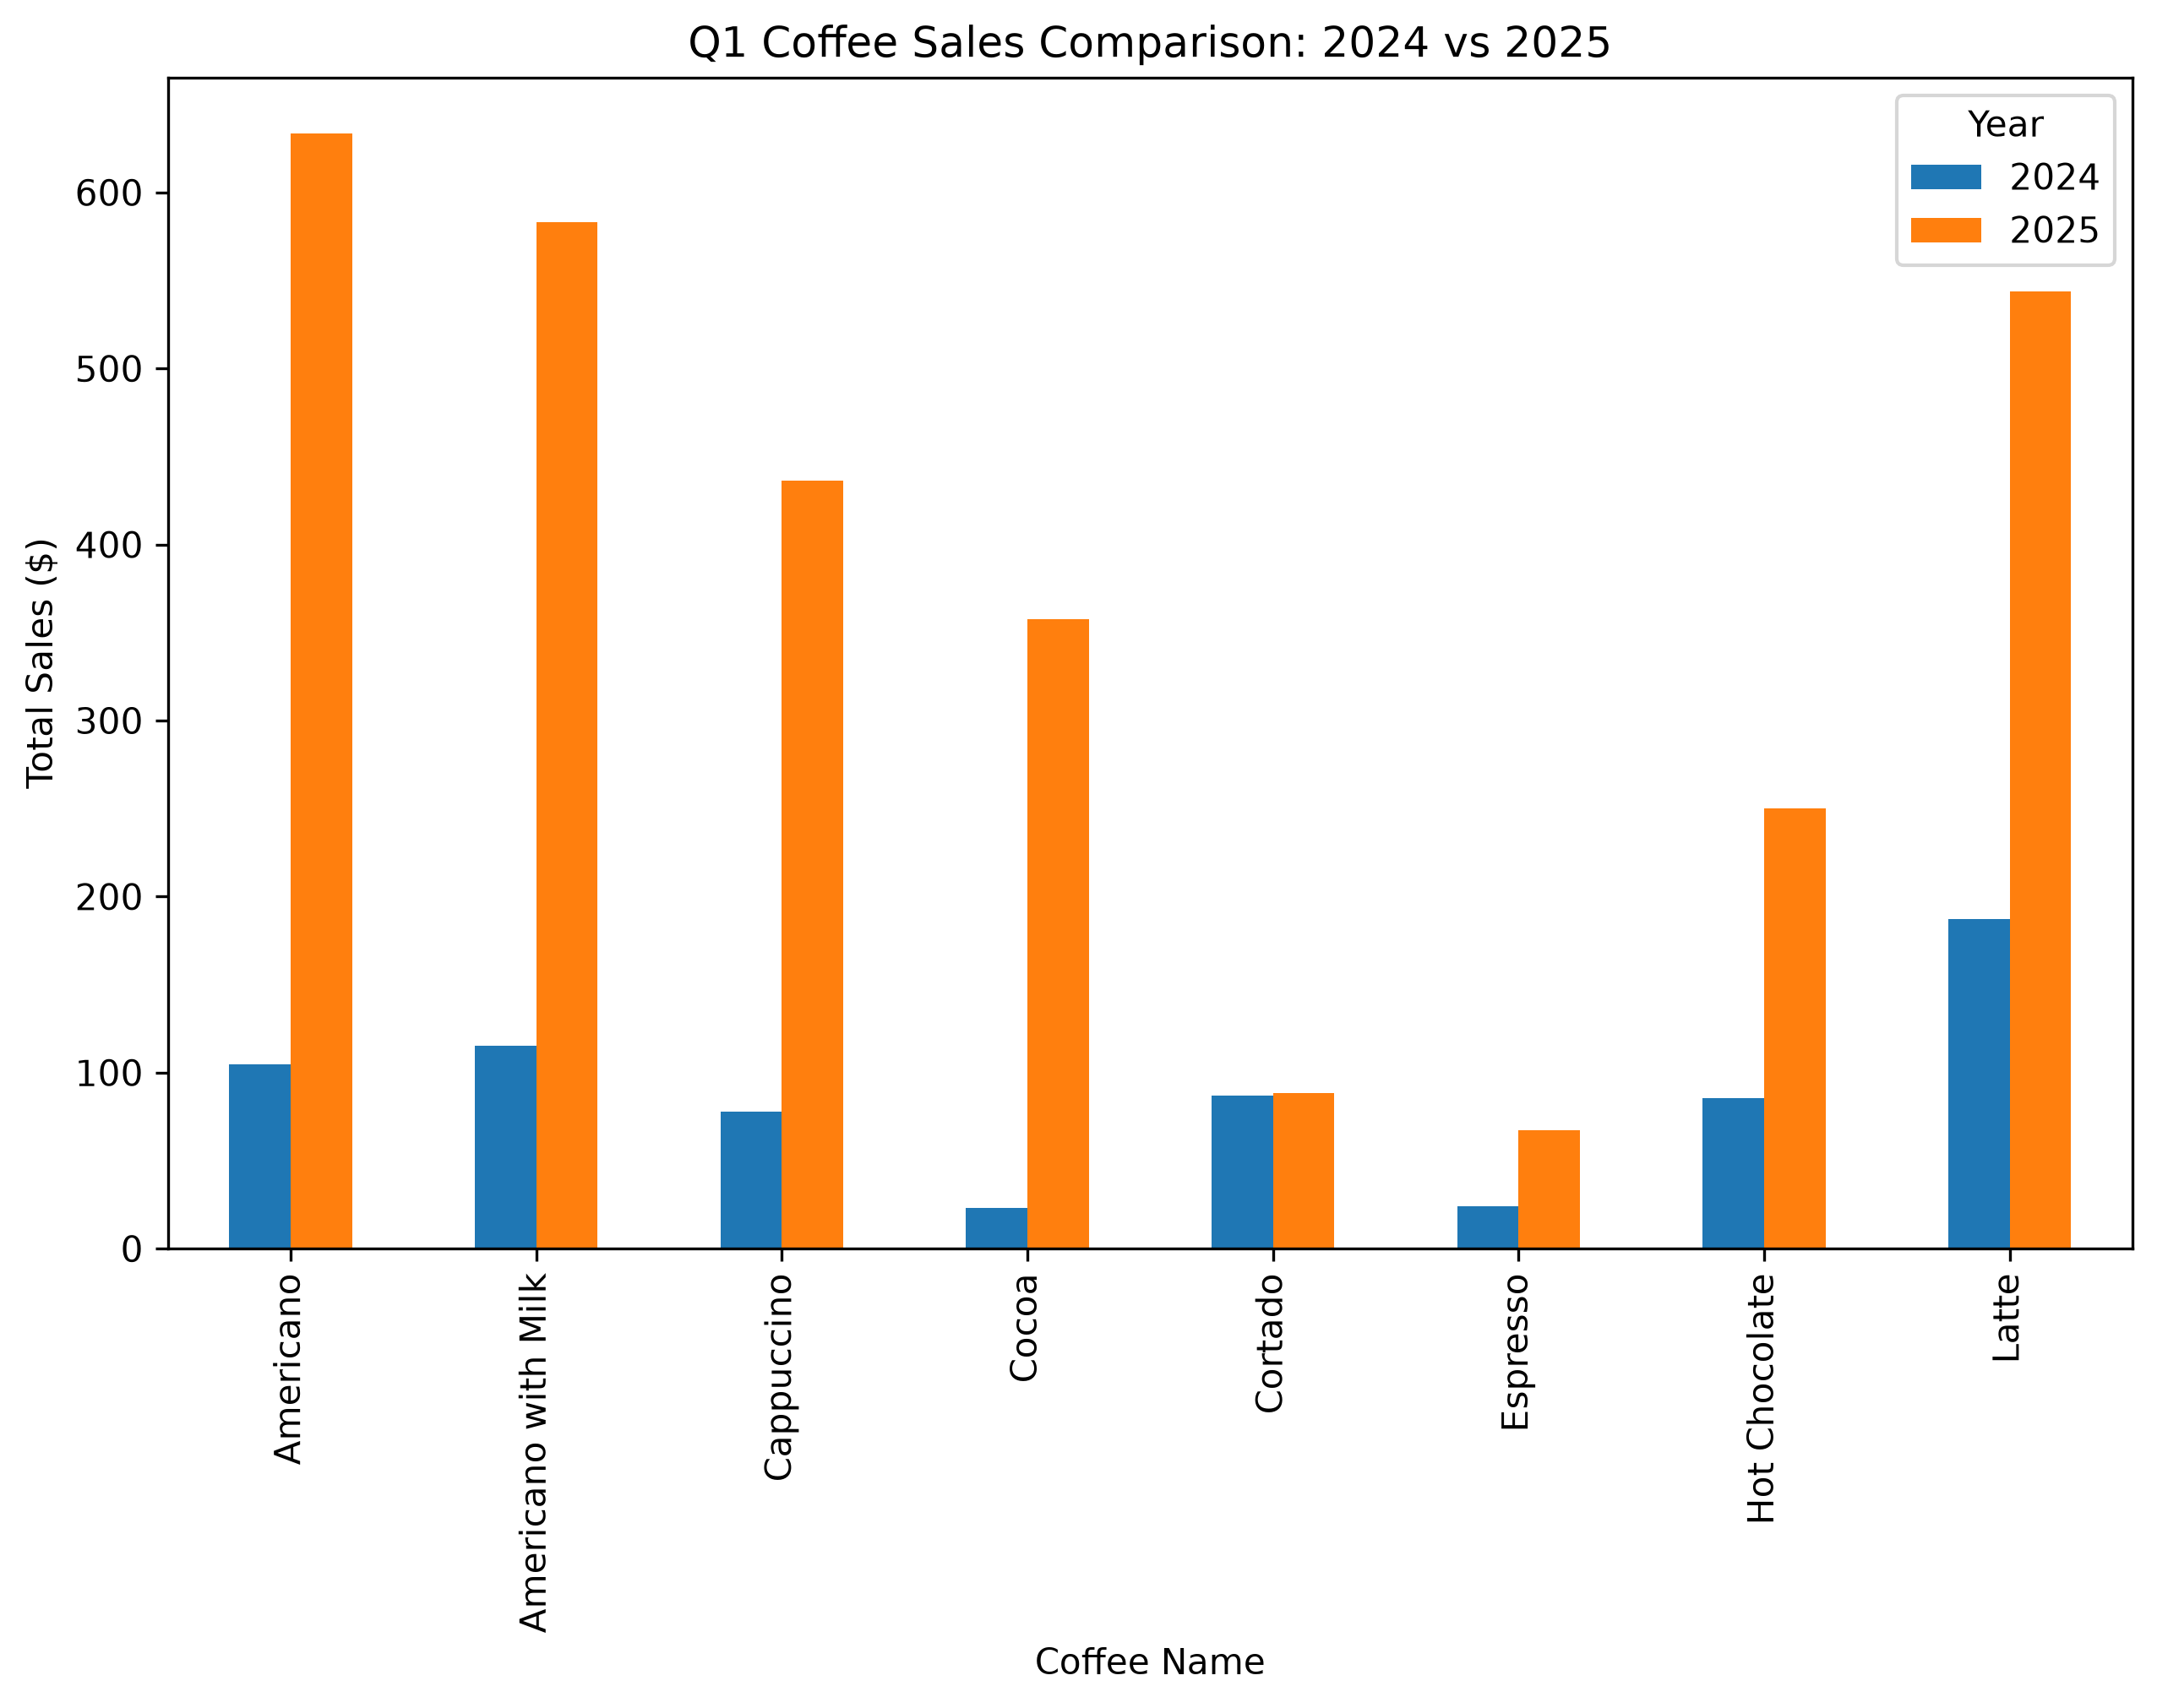


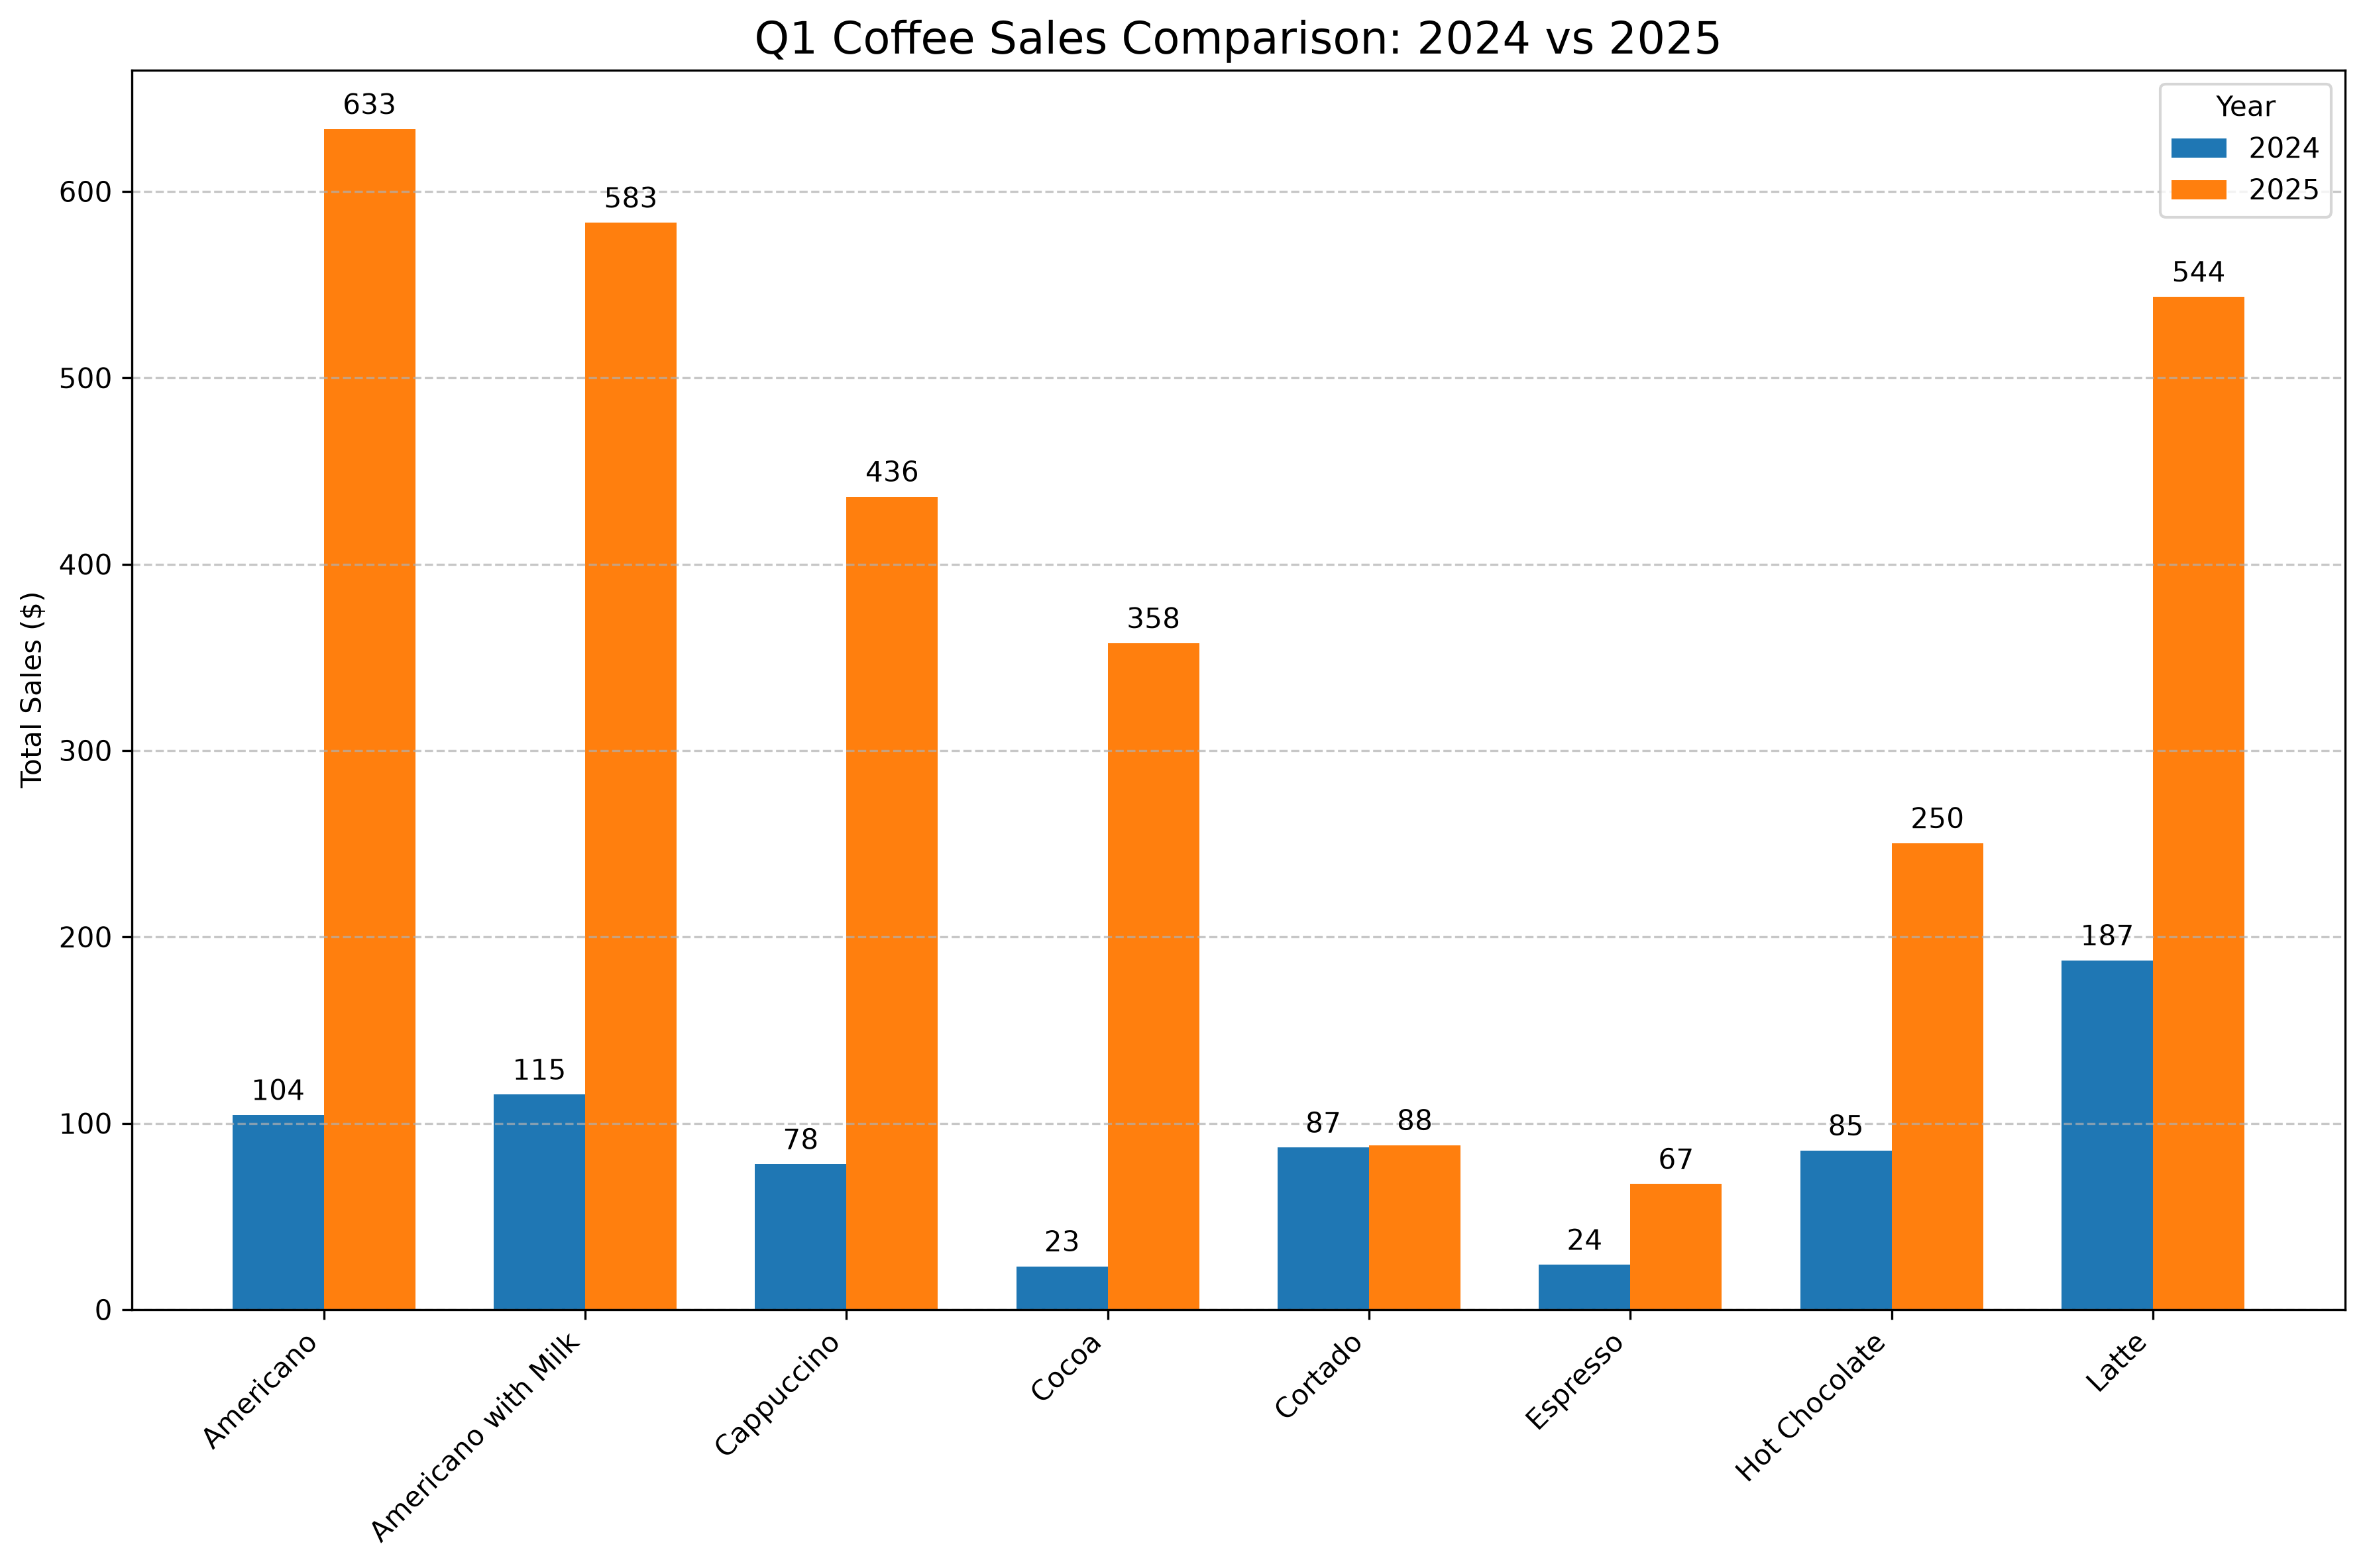

{'code_v1': "<execute_python>\nimport pandas as pd\nimport matplotlib.pyplot as plt\n\n# Filter for Q1 of 2024 and 2025\ndf_q1 = df[(df['quarter'] == 1) & (df['year'].isin([2024, 2025]))]\n\n# Aggregate sales by coffee name and year\nsales = (\n    df_q1.groupby(['year', 'coffee_name'])['price']\n    .sum()\n    .reset_index()\n)\n\n# Pivot for plotting\npivot = sales.pivot(index='coffee_name', columns='year', values='price').fillna(0)\n\n# Plot\nax = pivot.plot(kind='bar', figsize=(10, 6))\nax.set_title('Q1 Coffee Sales Comparison: 2024 vs 2025')\nax.set_xlabel('Coffee Name')\nax.set_ylabel('Total Sales ($)')\nax.legend(title='Year')\n\n# Save figure\nplt.savefig('drink_sales_v1.png', dpi=300, bbox_inches='tight')\nplt.close('all')\n</execute_python>",
 'chart_v1': 'drink_sales_v1.png',
 'feedback': 'The chart is functional but lacks polish. I added tick labels to the bars for clarity, improved the font size of the x-axis labels and rotated them to prevent overlap, and added a grid to

In [49]:
run_workflow(
        dataset_path=csv_path, 
        user_instructions=user_instructions,
        generation_model=generation_model,
        reflection_model=reflection_model,
        image_basename=image_basename
    )